# From one 625 nm photon to parity flips

Every LED pulse deposits the full energy of one 625 nm photon in the substrate. What changes when each LED pulse gets its own expected number of flips? Follow one channel from the initial absorber population to the trapped population, the expected flips $\Lambda_{\rm ch}$, and the realized count $S$. Then compare $S$ with a fixed-mean Poisson model at the same average yield.

All counts below are **simulated LED-induced truth for complete pulses**. Quiescent flips and reconstruction efficiency belong to the readout study. The example uses illustrative Al absorber and Hf trap parameters from the [QPD model, Eqs. 3, 14, 17 and B1](https://doi.org/10.1103/kqd2-spb1).

## Choose a channel

Edit the parameters below and run all cells. The collection fraction includes this channel's share of the energy and absorber pair breaking. To explore a specific geometry, replace 0.20 with the value of `diffusion_trapping_probability(absorber_length_um, trap_length_um)`.

For the symmetric channel, the mobile quasiparticles are shared equally between two 500 µm³ Hf traps. Their combined population is divided by 1,000 µm³ in the tunneling-rate calculation.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c, electron_volt, h
from scipy.stats import exponnorm, poisson

# Prefer the source tree containing this notebook over an installed package.
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/qpd").is_dir())
sys.path.insert(0, str(root / "src"))
from qpd import LEDEnergyModel, LEDPulseModel, diffusion_trapping_probability

wavelength_nm = 625.0
photon_energy_ev = h * c / (wavelength_nm * 1e-9 * electron_volt)
print(f"Substrate energy per pulse: {photon_energy_ev:.6f} eV")

model = LEDEnergyModel(
    deposited_energy_ev=photon_energy_ev,
    eta_ce=0.10,
    absorber_gap_ev=190e-6,
    fano_factor=0.20,
    trapping_probability=0.20,
    multiplication_gain=0.5 * 190 / 40,
    tunneling_constant_um3_s=20_000,
    qp_lifetime_s=0.001,
    trap_volume_um3=2 * 500,
)
n_pulses = 40_000
seed = 20261127

ink, teal, gold = "#25364A", "#007F78", "#C57822"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": ink, "text.color": ink, "font.size": 10,
                     "figure.dpi": 120, "axes.titlelocation": "left"})

spec = json.loads((root / "configs/siderius/led_standalone_snr2.json").read_text())
nominal = spec["parameters"]
led = LEDPulseModel(
    energy_model=model,
    mu=spec["burst_mu_s"],
    sigma=nominal["burst_sigma_s"]["nominal"],
    tau=nominal["burst_tau_s"]["nominal"],
    on_time=nominal["on_time_s"]["nominal"],
    off_time=nominal["off_time_s"]["nominal"],
)
print(f"Nominal EMG (ms): μ={1e3*led.mu:g}, σ={1e3*led.sigma:g}, τ={1e3*led.tau:g}")

Substrate energy per pulse: 1.983747 eV
Nominal EMG (ms): μ=0.2, σ=0.4, τ=0.8


## How the population becomes a count

The absorber mean is $\mu=E_{\rm dep}\eta_{\rm CE,ch}/\Delta_{\rm abs}$. The integer sampler targets variance $F\mu$, subject to the minimum feasible variance at that mean. Each absorber quasiparticle has capture probability $p$. Each capture contributes a fixed effective mobile yield $g$, giving $M=gN_{\rm cap}$ and $\Lambda_{\rm ch}=aM$ with $a=K\tau_{\rm qp}/V_{\rm tr}$. The LED simulator then draws $S\mid\Lambda_{\rm ch}\sim\mathrm{Poisson}(\Lambda_{\rm ch})$ and assigns flip times.

In [2]:
def simulate_pulses(led, count, run_seed):
    # End halfway between rising edges to include exactly count complete-pulse truths.
    duration = led.first_pulse_time + (count - 0.5) * led.period
    truth = led.sample(duration, np.random.default_rng(run_seed))
    assert len(truth.bursts) == count
    flips = np.array([burst.n_qp for burst in truth.bursts])
    return truth, flips

truth, flips = simulate_pulses(led, n_pulses, seed)
pop = truth.population
a = model.tunneling_constant_um3_s * model.qp_lifetime_s / model.trap_volume_um3
b = a * model.multiplication_gain  # integrated mean flips per captured quasiparticle
p = model.trapping_probability
mu = model.deposited_energy_ev * model.eta_ce / model.absorber_gap_ev
frac = mu % 1
v_abs = max(model.fano_factor * mu, frac * (1 - frac))
mean_flips = b * p * mu
variance_terms = np.array([mean_flips, b**2 * p * (1 - p) * mu, (b * p)**2 * v_abs])

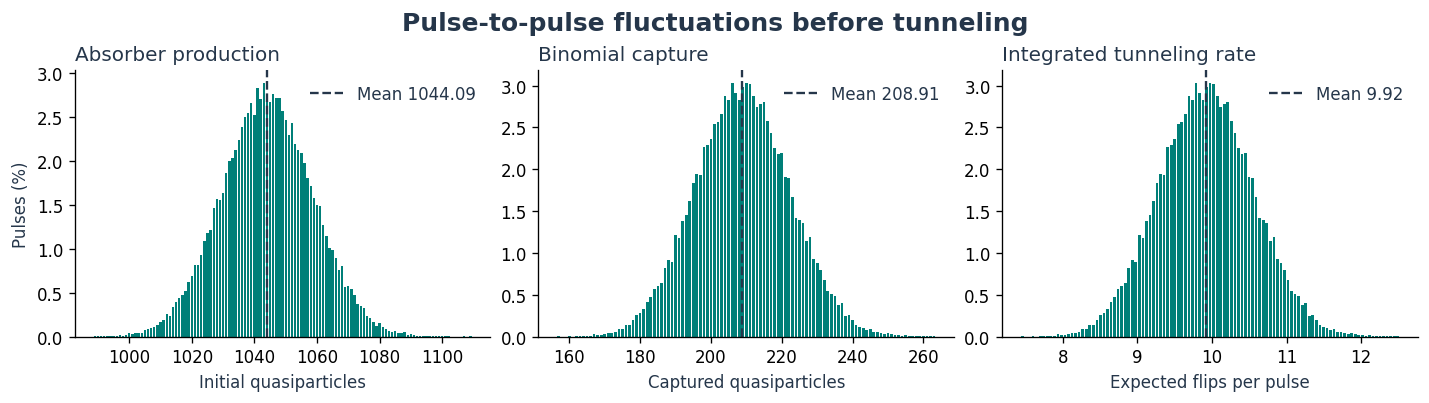

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11.8, 3.25), layout="constrained")
for ax, values, title, xlabel, step in zip(
    axes, [pop.absorber_qp, pop.captured_qp, pop.lambda_ch],
    ["Absorber production", "Binomial capture", "Integrated tunneling rate"],
    ["Initial quasiparticles", "Captured quasiparticles", "Expected flips per pulse"],
    [1, 1, b or 1],
):
    x, counts = np.unique(values, return_counts=True)
    ax.bar(x, counts / n_pulses * 100, width=step * 0.76, color=teal)
    ax.axvline(values.mean(), color=ink, ls="--", lw=1.4, label=f"Mean {values.mean():.2f}")
    ax.set(title=title, xlabel=xlabel)
    ax.legend(frameon=False)
axes[0].set_ylabel("Pulses (%)")
fig.suptitle("Pulse-to-pulse fluctuations before tunneling", fontsize=15, fontweight="bold")
plt.show()

## What changes relative to a fixed-mean Poisson count?

At the same mean, both models have shot-noise variance $\mathbb E[S]$. The energy model adds the variance in $\Lambda_{\rm ch}$. With $b=ag$, the binomial capture contribution is $b^2p(1-p)\mu$ and the absorber production contribution is $b^2p^2\operatorname{Var}(N_{\rm abs})$. Fixed multiplication scales both contributions. The right panel shows the absolute variance contributed by each stage.

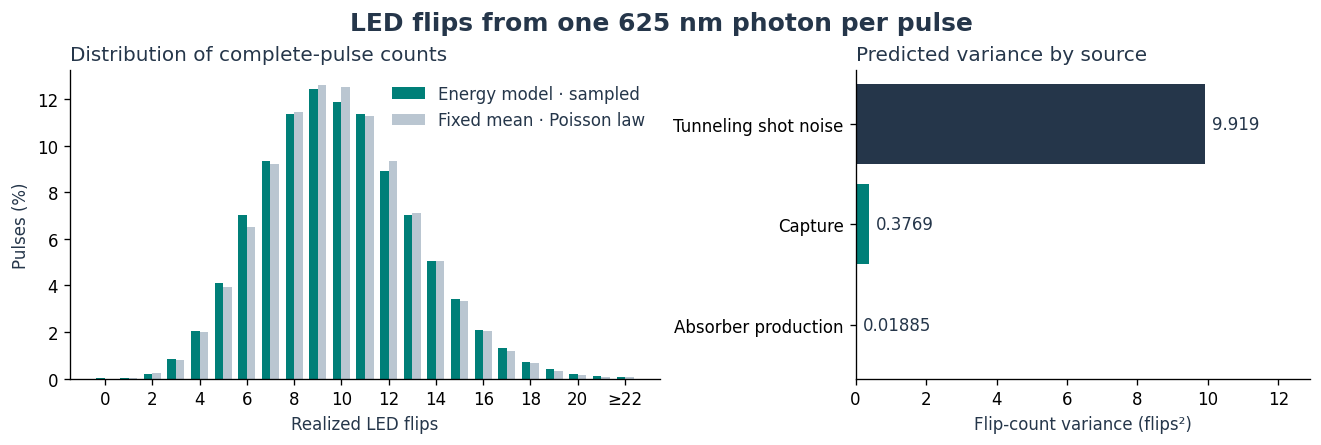

40,000 pulses        Sampled   Predicted
Mean flips             9.9117      9.9187
Flip variance         10.3278     10.3145
Variance of Λ          0.4027      0.3958


In [4]:
# Group the tail into the last bin so every simulated pulse is represented.
last = max(2, int(poisson.ppf(0.999, mean_flips)) + 1)
k = np.arange(last + 1)
measured = np.bincount(np.minimum(flips, last), minlength=last + 1) / n_pulses
baseline = np.r_[poisson.pmf(k[:-1], mean_flips), poisson.sf(last - 1, mean_flips)]

fig, (ax, budget) = plt.subplots(1, 2, figsize=(10.9, 3.6), layout="constrained",
                                 gridspec_kw={"width_ratios": [1.3, 1]})
ax.bar(k - 0.18, 100 * measured, 0.36, color=teal, label="Energy model · sampled")
ax.bar(k + 0.18, 100 * baseline, 0.36, color="#BAC6D1", label="Fixed mean · Poisson law")
ax.set(title="Distribution of complete-pulse counts", xlabel="Realized LED flips", ylabel="Pulses (%)")
tick_step = max(1, last // 8)
ticks = np.unique(np.r_[np.arange(0, last, tick_step), last])
ax.set_xticks(ticks, [str(t) if t < last else f"≥{last}" for t in ticks])
ax.legend(frameon=False)
bars = budget.barh(["Tunneling shot noise", "Capture", "Absorber production"],
                   variance_terms, color=[ink, teal, gold])
budget.invert_yaxis()
budget.bar_label(bars, labels=[f"{v:.4g}" for v in variance_terms], padding=4)
budget.set_xlim(0, max(variance_terms.max() * 1.3, 0.01))
budget.set(title="Predicted variance by source", xlabel="Flip-count variance (flips²)")
fig.suptitle(f"LED flips from one {wavelength_nm:g} nm photon per pulse", fontsize=15, fontweight="bold")
plt.show()

print(f"{n_pulses:,} pulses      {'Sampled':>9}  {'Predicted':>10}")
for label, observed, expected in [("Mean flips", flips.mean(), mean_flips),
                                  ("Flip variance", flips.var(), variance_terms.sum()),
                                  ("Variance of Λ", pop.lambda_ch.var(), variance_terms[1:].sum())]:
    print(f"{label:<19} {observed:9.4f}  {expected:10.4f}")

## Where do the flips land in time?

The [nominal pipeline template](../configs/siderius/led_standalone_snr2.json) is an exponentially modified Gaussian (EMG) with Gaussian location 0.2 ms, width 0.4 ms, and exponential decay 0.8 ms. The simulator resamples negative delays. Its 50 µs excitation window adds a mean offset of only 25 µs.

The histogram sums all LED-induced flips relative to their own rising edges and divides by the number of pulses and bin width. The template curve has area equal to the predicted mean flips per pulse.

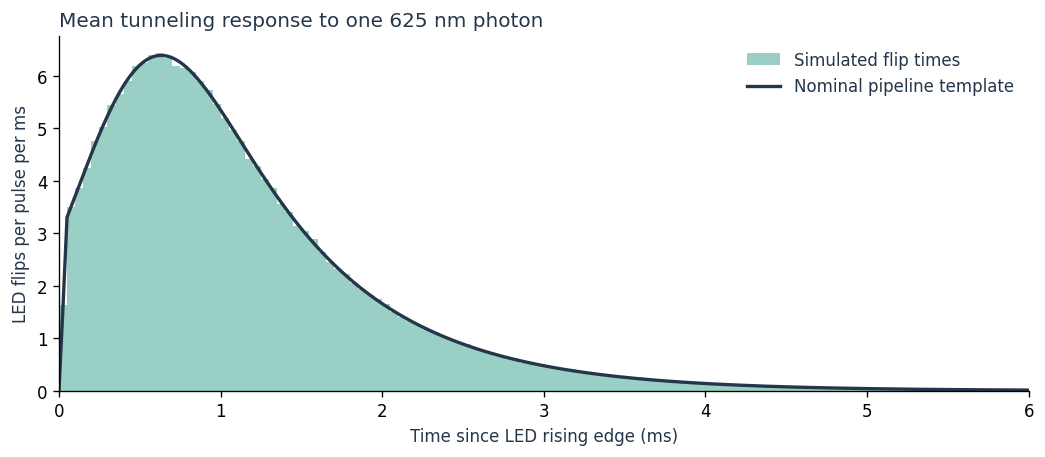

Flips within 3 ms: 96.21%  |  Template peak: 0.630 ms


In [5]:
delay_ms = 1e3 * np.concatenate([burst.event_times - burst.t_arrival for burst in truth.bursts])
edges = np.linspace(0, 6, 121)
counts, _ = np.histogram(delay_ms, bins=edges)

# For a uniform excitation time, the delay density is the difference of
# two causal EMG CDF values divided by the excitation width.
emg = exponnorm(led.tau / led.sigma, loc=1e3 * led.mu, scale=1e3 * led.sigma)
width_ms = 1e3 * led.on_time
t = np.linspace(0, edges[-1], 1201)
def causal_cdf(x):
    return (emg.cdf(np.maximum(x, 0)) - emg.cdf(0)) / emg.sf(0)

density = (causal_cdf(t) - causal_cdf(t - width_ms)) / width_ms
fig, ax = plt.subplots(figsize=(8.6, 3.7), layout="constrained")
ax.stairs(counts / (n_pulses * np.diff(edges)), edges, fill=True, color="#9ACFC5",
          label="Simulated flip times")
ax.plot(t, mean_flips * density, color=ink, lw=2, label="Nominal pipeline template")
ax.set(xlabel="Time since LED rising edge (ms)", ylabel="LED flips per pulse per ms",
       title=f"Mean tunneling response to one {wavelength_nm:g} nm photon", xlim=(0, edges[-1]), ylim=(0, None))
ax.legend(frameon=False)
plt.show()
if delay_ms.size:
    print(f"Flips within 3 ms: {np.mean(delay_ms < 3):.2%}  |  Template peak: {t[density.argmax()]:.3f} ms")

The first 30 consecutive pulses show how individual realizations sample the same timing template. Each dot marks one flip.

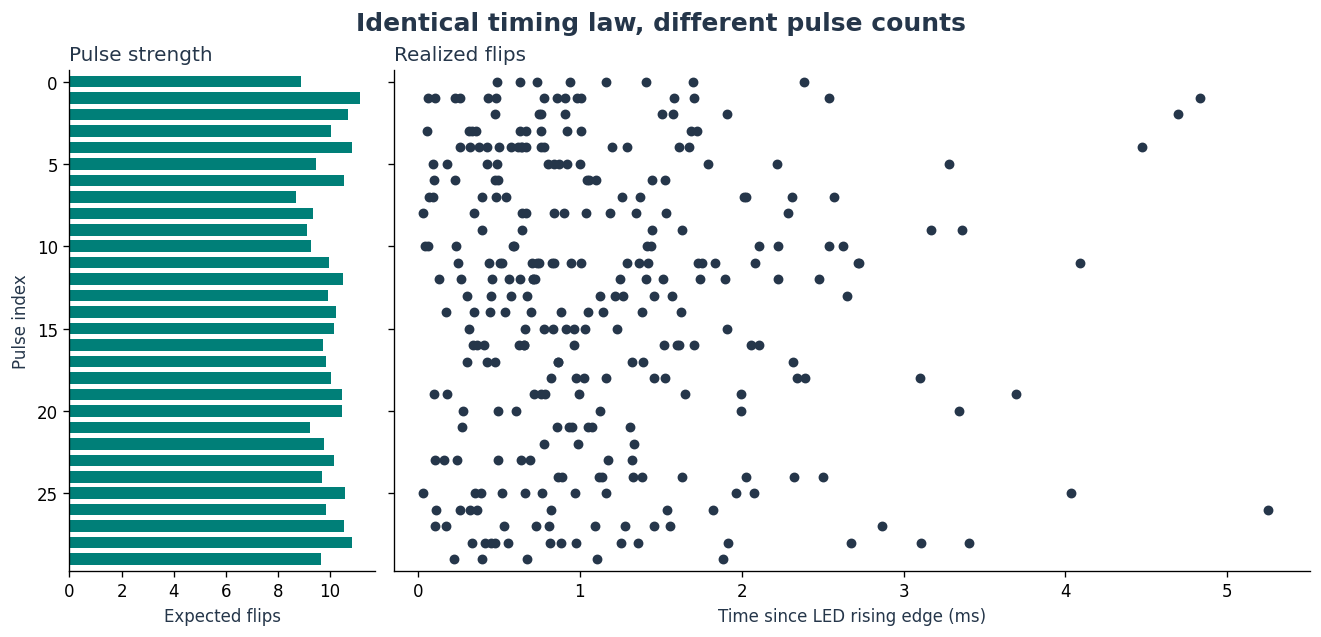

In [6]:
rows = min(30, n_pulses)
fig, (strength, raster) = plt.subplots(1, 2, figsize=(10.9, 5.2), sharey=True,
                                       gridspec_kw={"width_ratios": [1, 3]}, layout="constrained")
pulse_index = np.arange(rows)
strength.barh(pulse_index, pop.lambda_ch[:rows], height=0.70, color=teal)
strength.set(xlabel="Expected flips", ylabel="Pulse index", title="Pulse strength")
for i, burst in enumerate(truth.bursts[:rows]):
    delay_ms = 1e3 * (burst.event_times - burst.t_arrival)
    raster.scatter(delay_ms, np.full(delay_ms.size, i), s=24, color=ink)
raster.set(xlabel="Time since LED rising edge (ms)", title="Realized flips")
strength.set_ylim(rows - 0.3, -0.7)
raster.set_xlim(left=-0.15)
fig.suptitle("Identical timing law, different pulse counts", fontsize=15, fontweight="bold")
plt.show()

Most variance comes from counting individual crossings. To explore when capture fluctuations become more visible, increase the tunneling constant and rerun. The shot-noise term grows linearly in crossings per capture, while the two population terms grow quadratically.